In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/SuperMarket Analysis.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (1000, 17)

Columns:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

First 5 Rows:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [2]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

Missing Values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Duplicate Rows: 0

Data Types:
Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Sales                      float64
Date                        object
Time                        object
Payment                   

,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.672130,2.649463e+01,10.080000,32.875000,55.230000,77.935000,99.960000
Quantity,1000.0,5.510000,2.923431e+00,1.000000,3.000000,5.000000,8.000000,10.000000
Tax 5%,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Sales,1000.0,322.966749,2.458853e+02,10.678500,124.422375,253.848000,471.350250,1042.650000
cogs,1000.0,307.587380,2.341765e+02,10.170000,118.497500,241.760000,448.905000,993.000000
gross margin percentage,1000.0,4.761905,6.131498e-14,4.761905,4.761905,4.761905,4.761905,4.761905
gross income,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Rating,1000.0,6.972700,1.718580e+00,4.000000,5.500000,7.000000,8.500000,10.000000


In [3]:
categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Branch
Branch
Alex     340
Cairo    332
Giza     328
Name: count, dtype: int64

City
City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

Customer type
Customer type
Member    565
Normal    435
Name: count, dtype: int64

Gender
Gender
Female    571
Male      429
Name: count, dtype: int64

Product line
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64

Payment
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


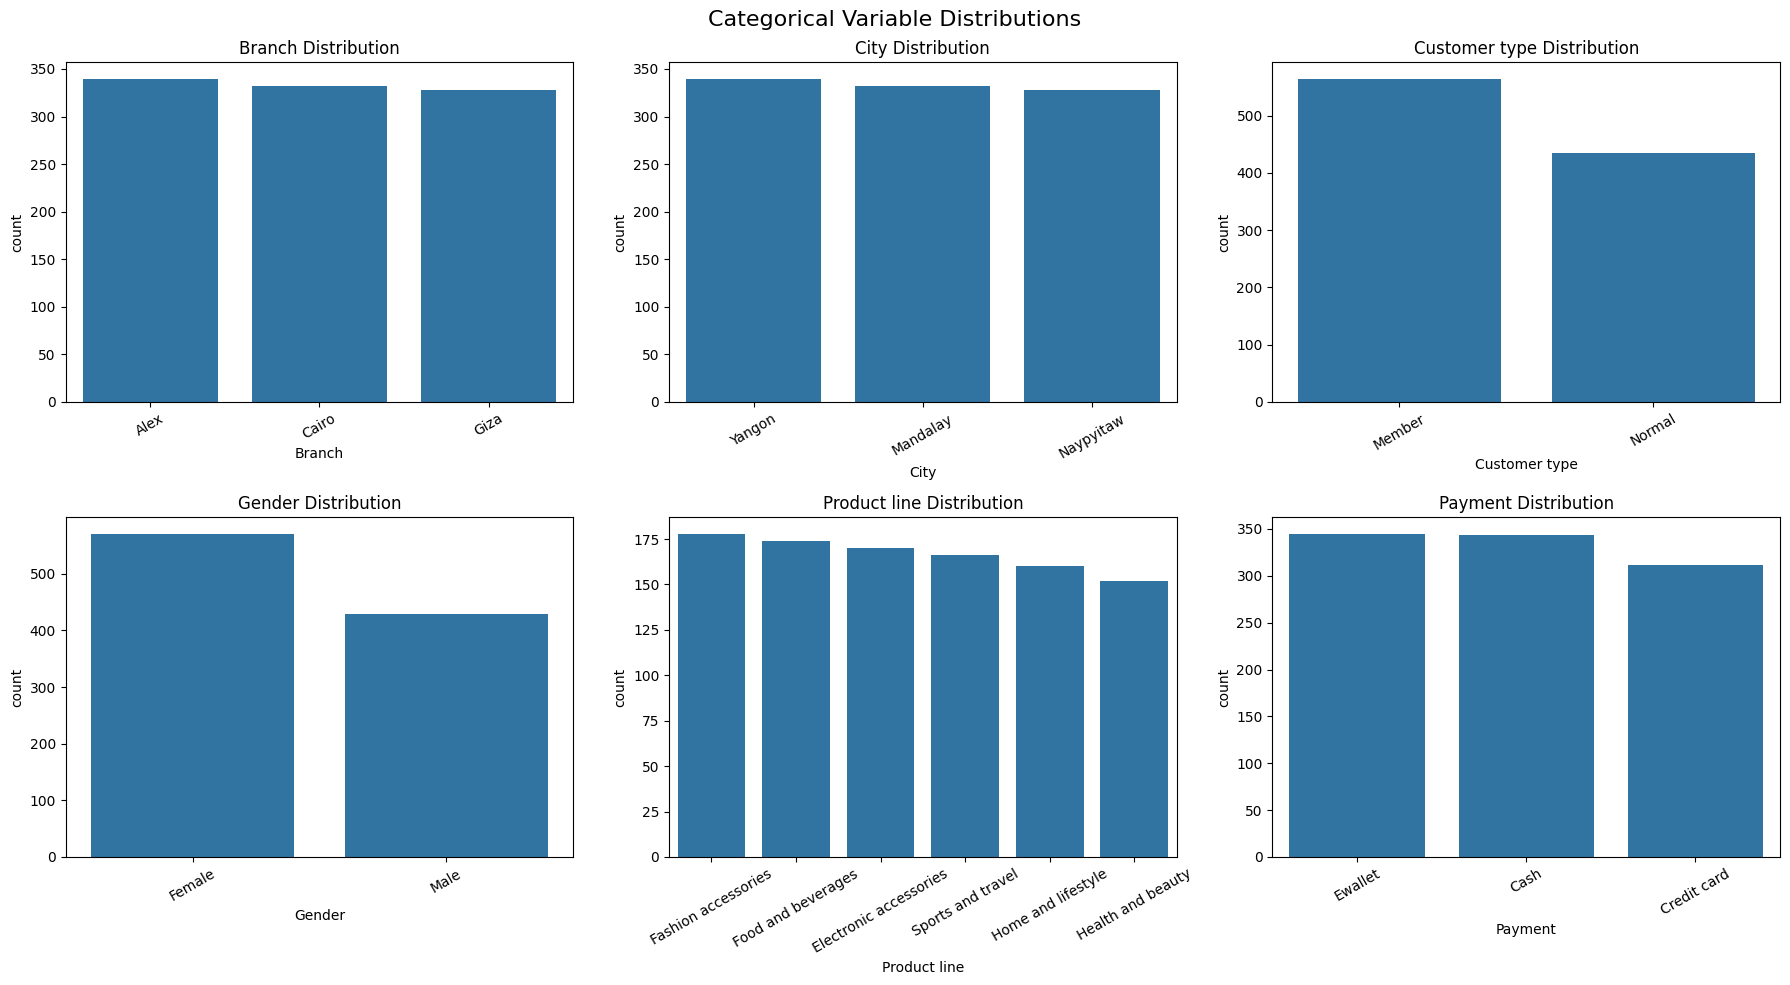

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/SuperMarket Analysis.csv")

categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flatten(), categorical_columns):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"{col} Distribution")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Categorical Variable Distributions", fontsize=16)
plt.tight_layout()
plt.show()

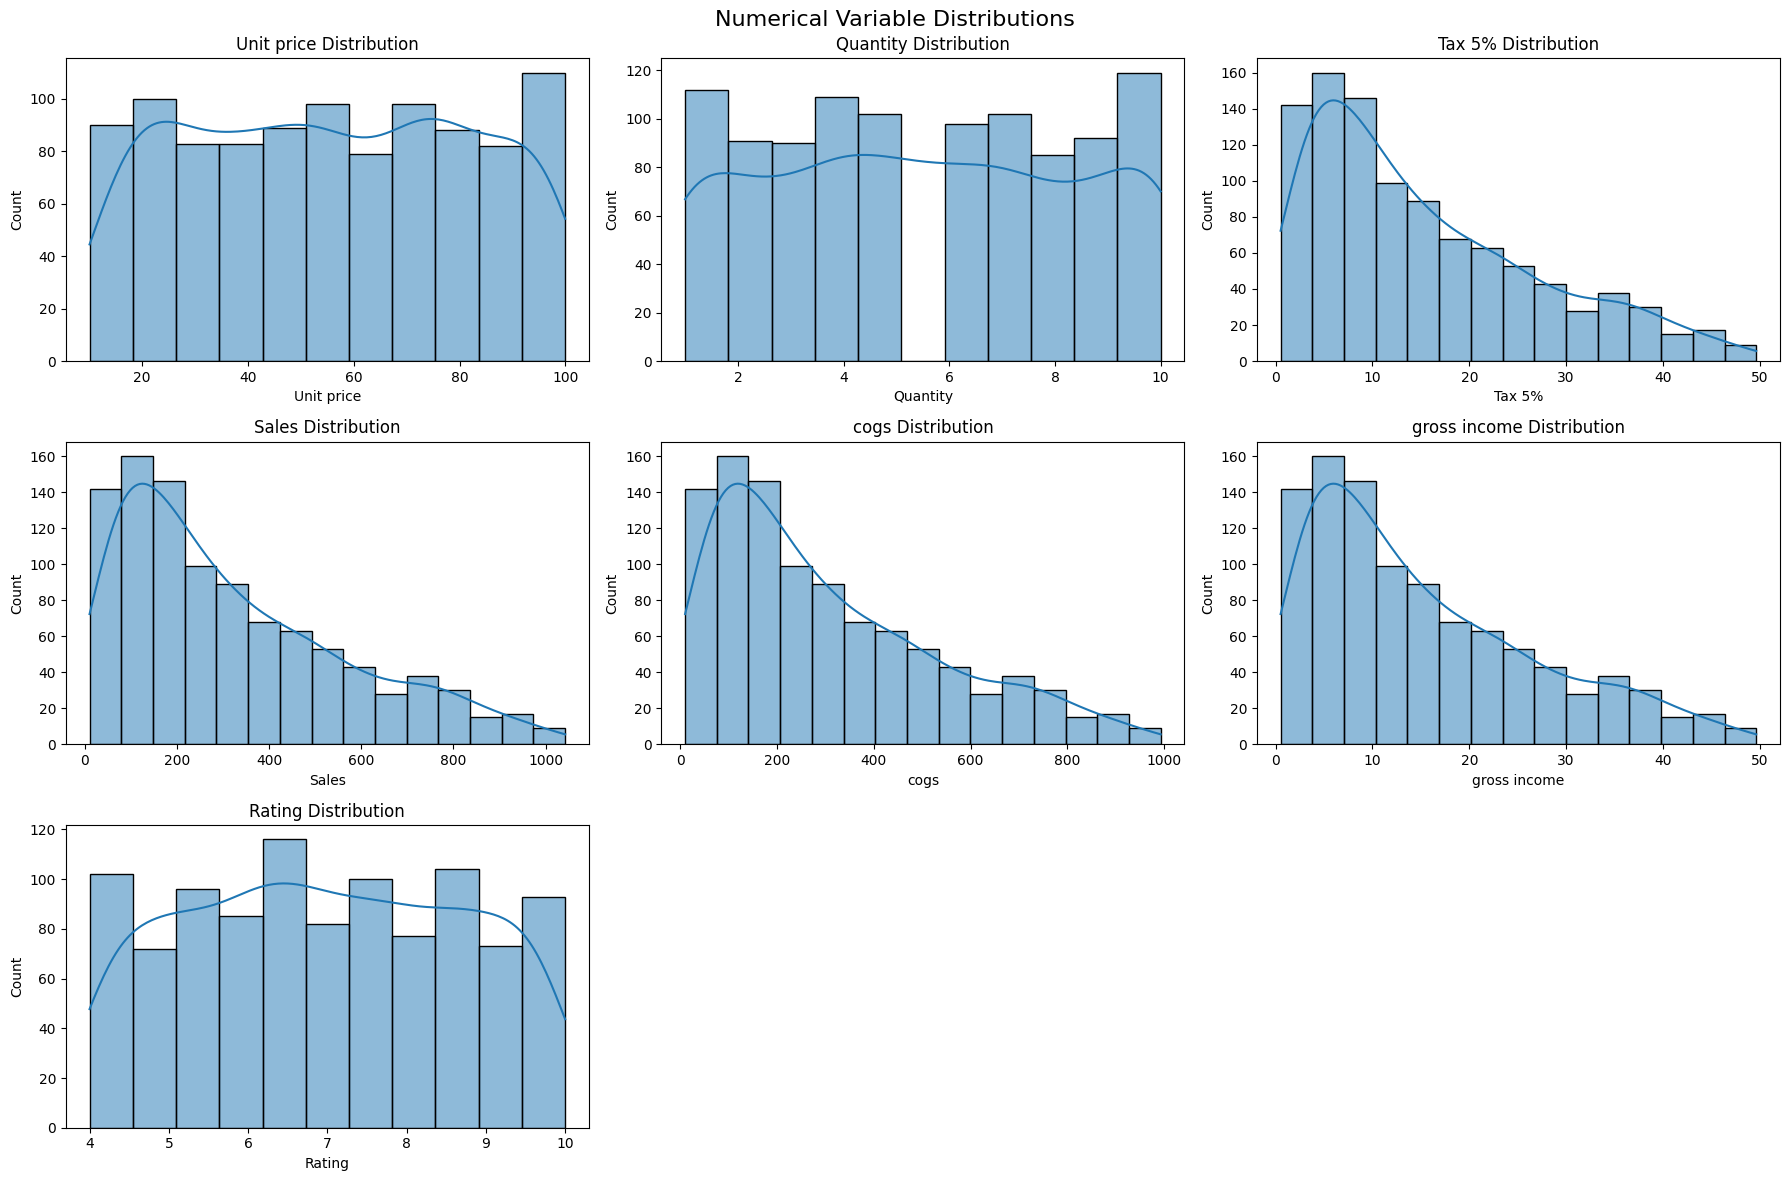

In [7]:
numerical_columns = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Sales",
    "cogs",
    "gross income",
    "Rating"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for ax, col in zip(axes.flatten(), numerical_columns):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"{col} Distribution")

# Hide unused subplot
for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.suptitle("Numerical Variable Distributions", fontsize=16)
plt.tight_layout()
plt.show()

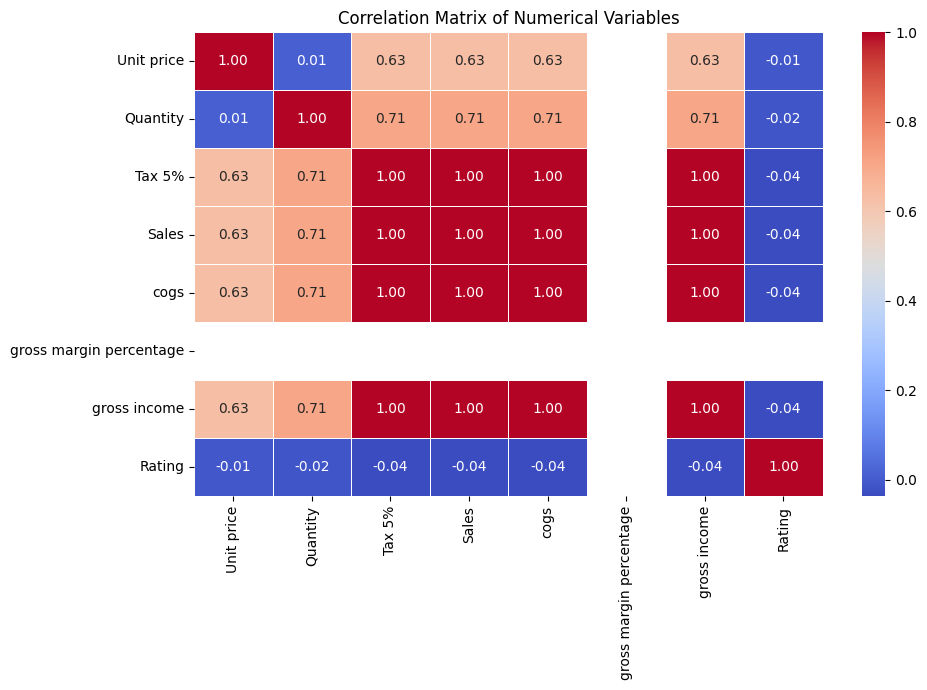

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numerical_data = df.select_dtypes(include=np.number)

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

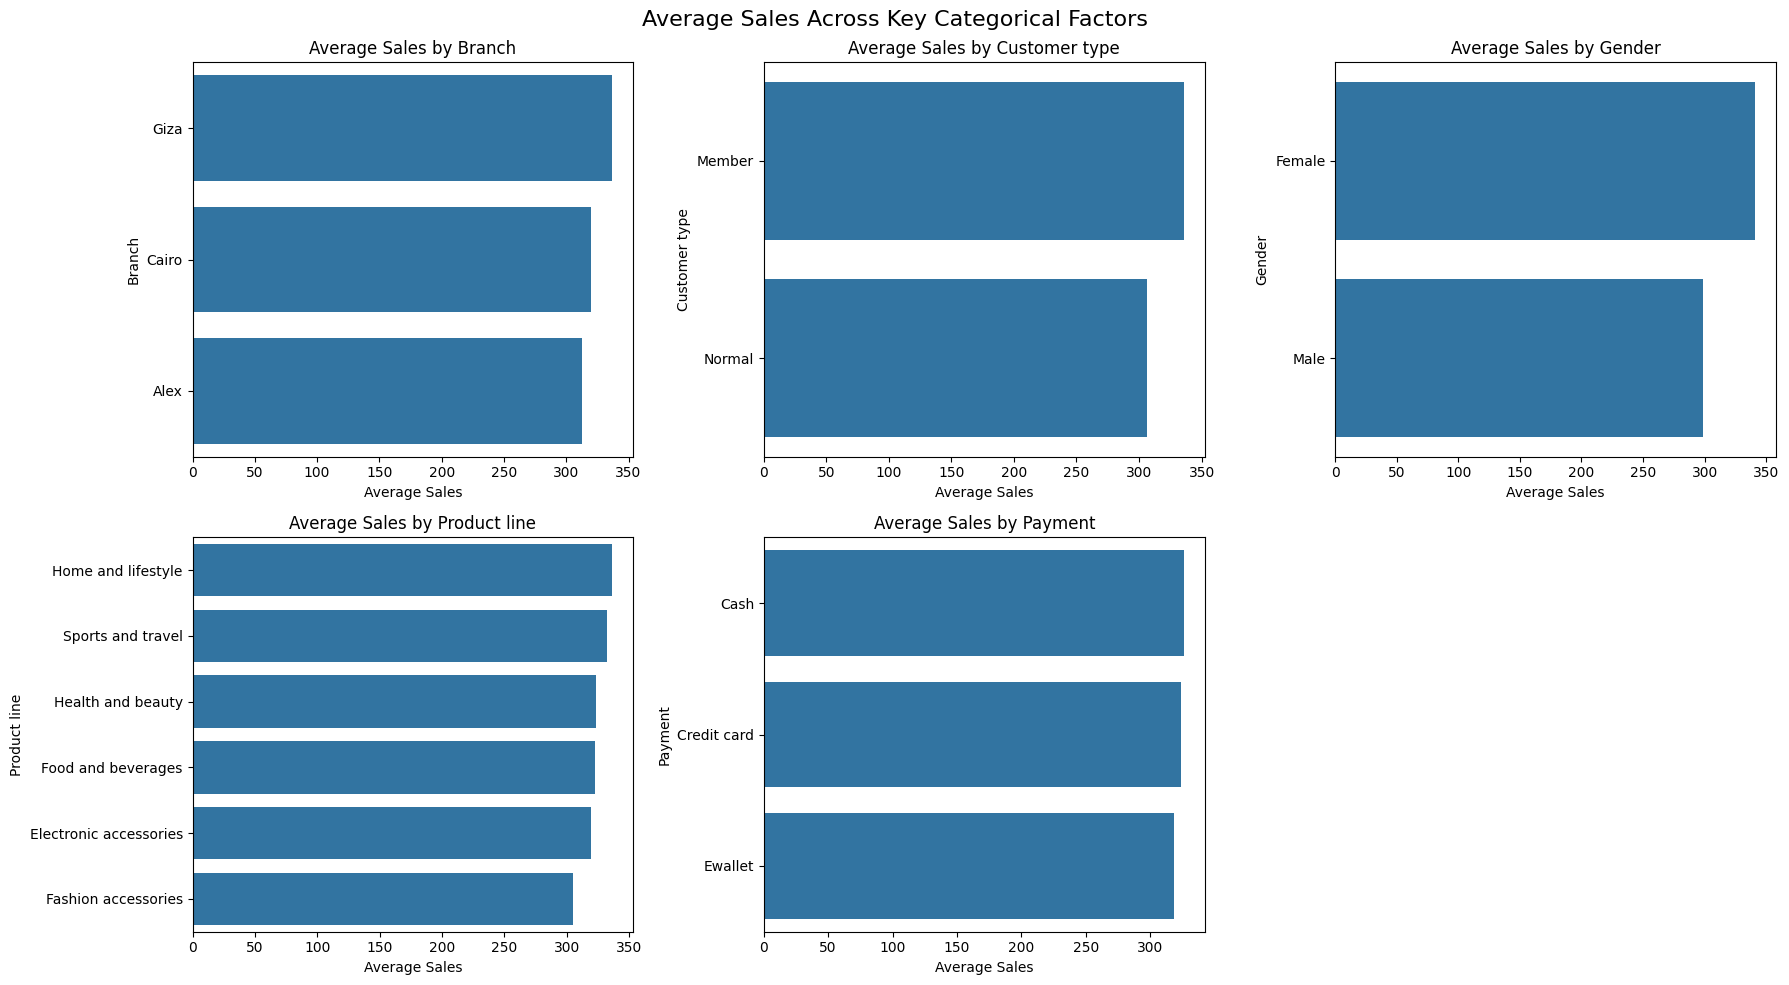

In [10]:
sales_factors = [
    "Branch",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flatten(), sales_factors):
    sales_by_category = df.groupby(col)["Sales"].mean().sort_values(ascending=False)
    sns.barplot(
        x=sales_by_category.values,
        y=sales_by_category.index,
        ax=ax
    )
    ax.set_title(f"Average Sales by {col}")
    ax.set_xlabel("Average Sales")
    ax.set_ylabel(col)

axes.flatten()[-1].set_visible(False)

plt.suptitle("Average Sales Across Key Categorical Factors", fontsize=16)
plt.tight_layout()
plt.show()

                        Total_Sales  Average_Sales
Product line                                      
Food and beverages       56144.8440     322.671517
Sports and travel        55122.8265     332.065220
Electronic accessories   54337.5315     319.632538
Fashion accessories      54305.8950     305.089298
Home and lifestyle       53861.9130     336.636956
Health and beauty        49193.7390     323.643020


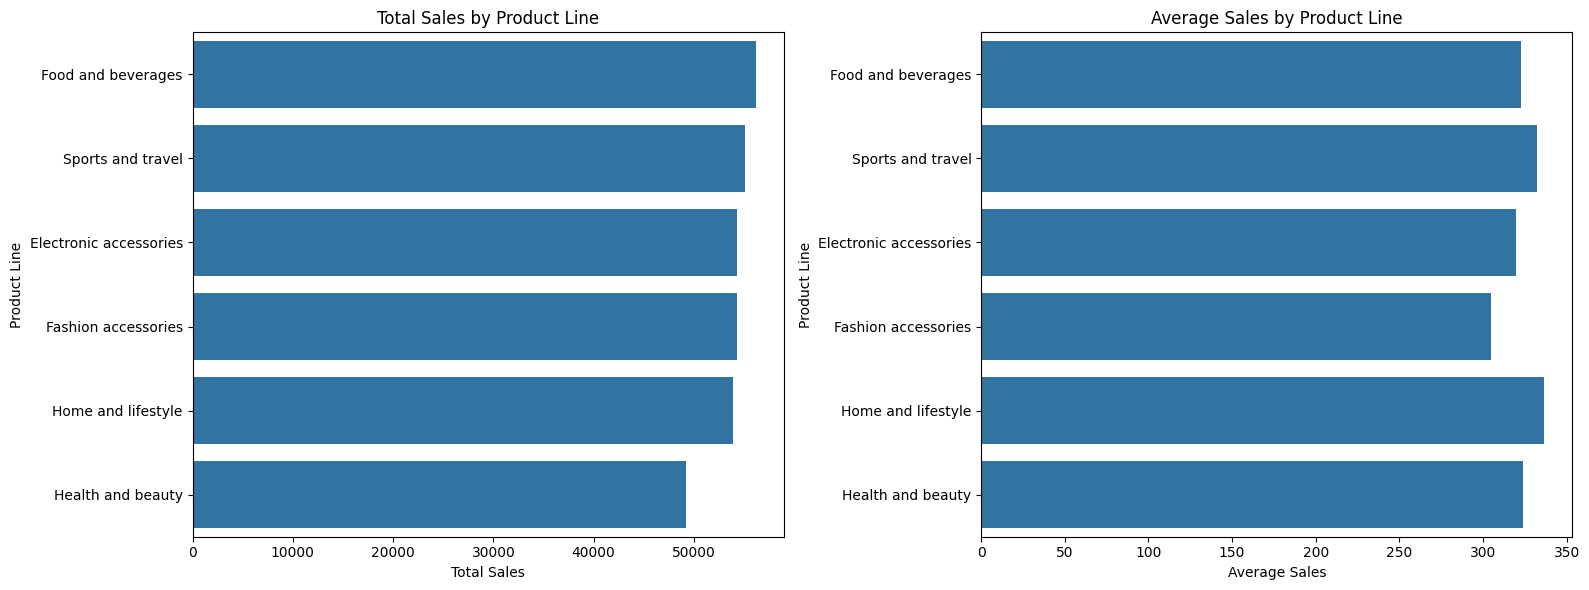

In [11]:
product_sales = df.groupby("Product line")["Sales"].agg(
    Total_Sales="sum",
    Average_Sales="mean"
).sort_values("Total_Sales", ascending=False)

print(product_sales)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=product_sales["Total_Sales"],
    y=product_sales.index,
    ax=axes[0]
)
axes[0].set_title("Total Sales by Product Line")
axes[0].set_xlabel("Total Sales")
axes[0].set_ylabel("Product Line")

sns.barplot(
    x=product_sales["Average_Sales"],
    y=product_sales.index,
    ax=axes[1]
)
axes[1].set_title("Average Sales by Product Line")
axes[1].set_xlabel("Average Sales")
axes[1].set_ylabel("Product Line")

plt.tight_layout()
plt.show()

Monthly Sales:
Month
2019-01    116291.868
2019-02     97219.374
2019-03    109455.507
Name: Sales, dtype: float64


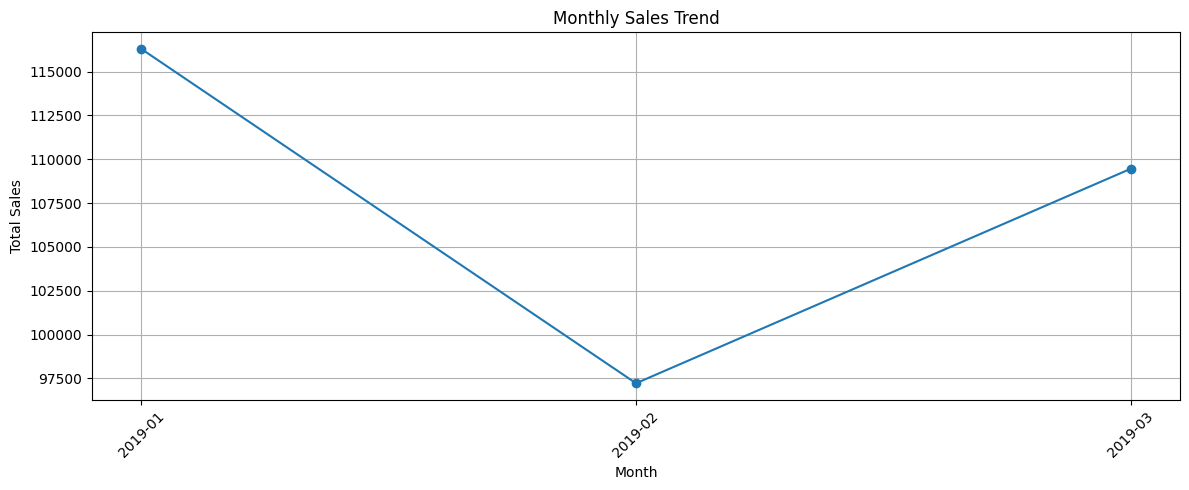

In [12]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

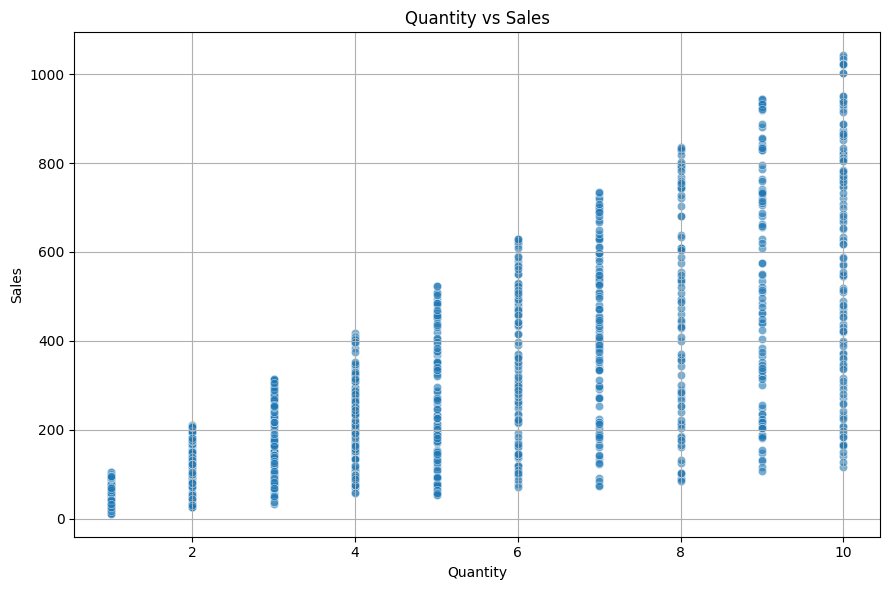

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Sales",
    alpha=0.6
)

plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_539/275711778.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Hour"] = pd.to_datetime(df["Time"]).dt.hour


      Total_Sales  Average_Sales  Transactions
Hour                                          
10     31421.4810     311.103772           101
11     30377.3295     337.525883            90
12     26065.8825     292.875084            89
13     34723.2270     337.118709           103
14     30828.3990     371.426494            83
15     31179.5085     305.681456           102
16     25226.3235     327.614591            77
17     24445.2180     330.340784            74
18     26030.3400     279.896129            93
19     39699.5130     351.323124           113
20     22969.5270     306.260360            75


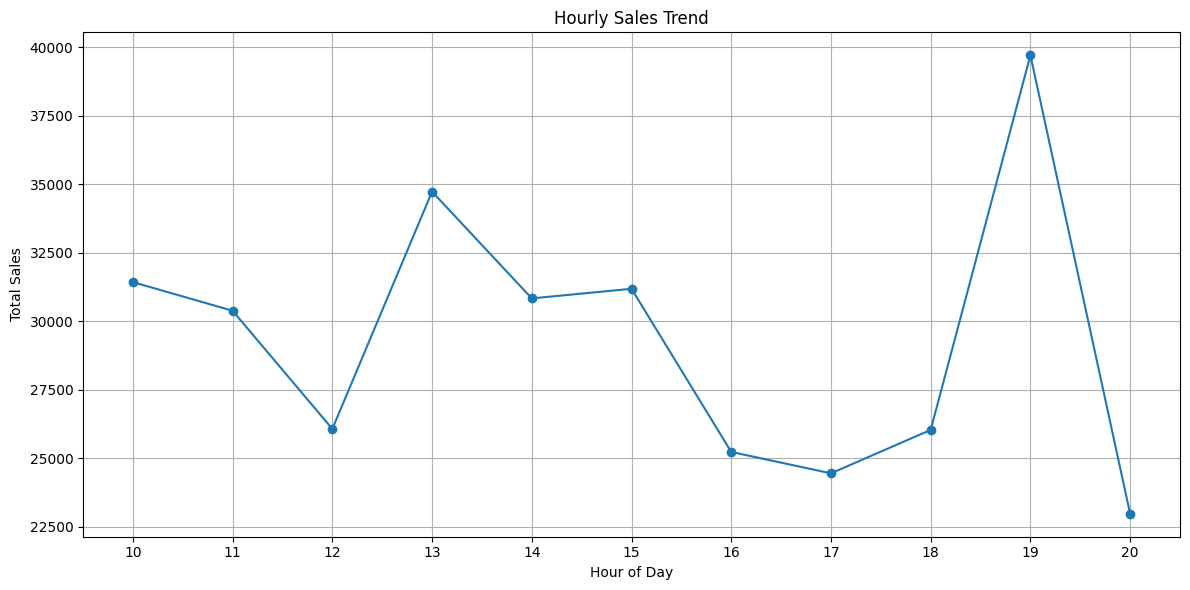

In [14]:
df["Hour"] = pd.to_datetime(df["Time"]).dt.hour

hourly_sales = df.groupby("Hour")["Sales"].agg(
    Total_Sales="sum",
    Average_Sales="mean",
    Transactions="count"
)

print(hourly_sales)

plt.figure(figsize=(12, 6))
plt.plot(
    hourly_sales.index,
    hourly_sales["Total_Sales"],
    marker="o"
)

plt.title("Hourly Sales Trend")
plt.xlabel("Hour of Day")
plt.ylabel("Total Sales")
plt.xticks(hourly_sales.index)
plt.grid(True)
plt.tight_layout()
plt.show()

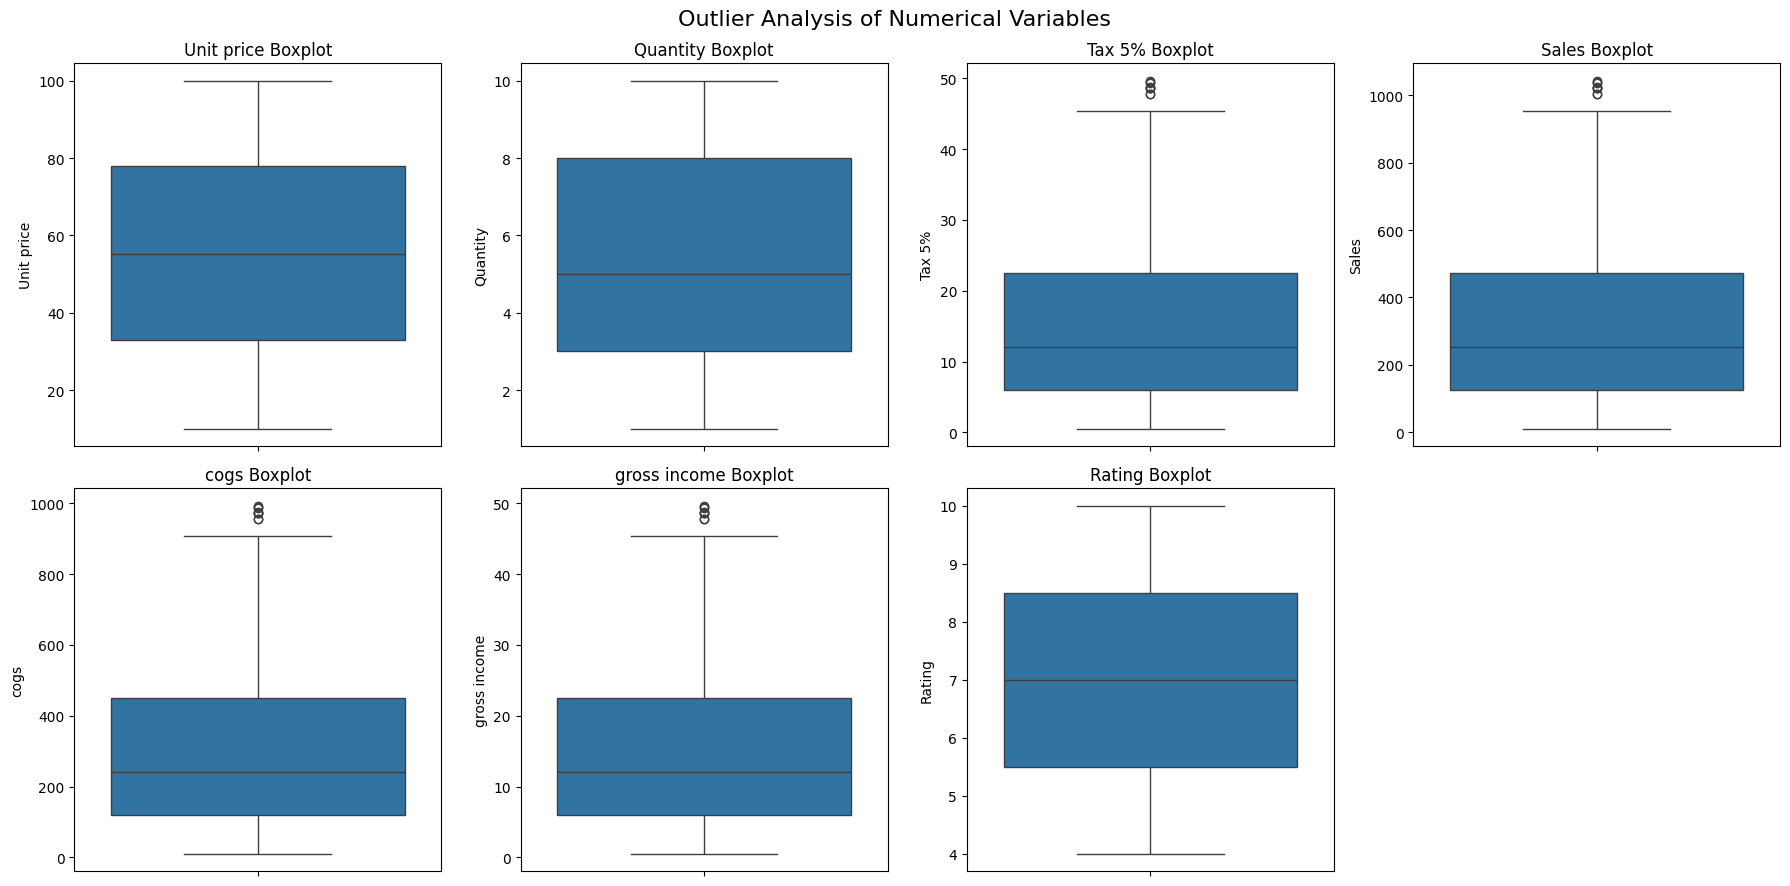

In [15]:
boxplot_columns = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Sales",
    "cogs",
    "gross income",
    "Rating"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, col in zip(axes.flatten(), boxplot_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"{col} Boxplot")

# Hide unused subplot
for ax in axes.flatten()[len(boxplot_columns):]:
    ax.set_visible(False)

plt.suptitle("Outlier Analysis of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
outlier_summary = []

for col in boxplot_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Variable,Lower Bound,Upper Bound,Outlier Count
0,Unit price,-34.715000,145.525000,0
1,Quantity,-4.500000,15.500000,0
2,Tax 5%,-18.855688,47.225813,9
3,Sales,-395.969438,991.742062,9
4,cogs,-377.113750,944.516250,9
5,gross income,-18.855688,47.225813,9
6,Rating,1.000000,13.000000,0


In [17]:
key_insights = {
    "Metric": [
        "Highest total sales product line",
        "Lowest total sales product line",
        "Highest average sales product line",
        "Highest average sales branch",
        "Highest average sales customer type",
        "Highest average sales gender",
        "Highest average sales payment method",
        "Highest sales hour",
        "Highest sales month"
    ],
    "Finding": [
        df.groupby("Product line")["Sales"].sum().idxmax(),
        df.groupby("Product line")["Sales"].sum().idxmin(),
        df.groupby("Product line")["Sales"].mean().idxmax(),
        df.groupby("Branch")["Sales"].mean().idxmax(),
        df.groupby("Customer type")["Sales"].mean().idxmax(),
        df.groupby("Gender")["Sales"].mean().idxmax(),
        df.groupby("Payment")["Sales"].mean().idxmax(),
        hourly_sales["Total_Sales"].idxmax(),
        monthly_sales.idxmax()
    ]
}

key_insights_df = pd.DataFrame(key_insights)

display(key_insights_df)

,Metric,Finding
0,Highest total sales product line,Food and beverages
1,Lowest total sales product line,Health and beauty
2,Highest average sales product line,Home and lifestyle
3,Highest average sales branch,Giza
4,Highest average sales customer type,Member
5,Highest average sales gender,Female
6,Highest average sales payment method,Cash
7,Highest sales hour,19
8,Highest sales month,2019-01


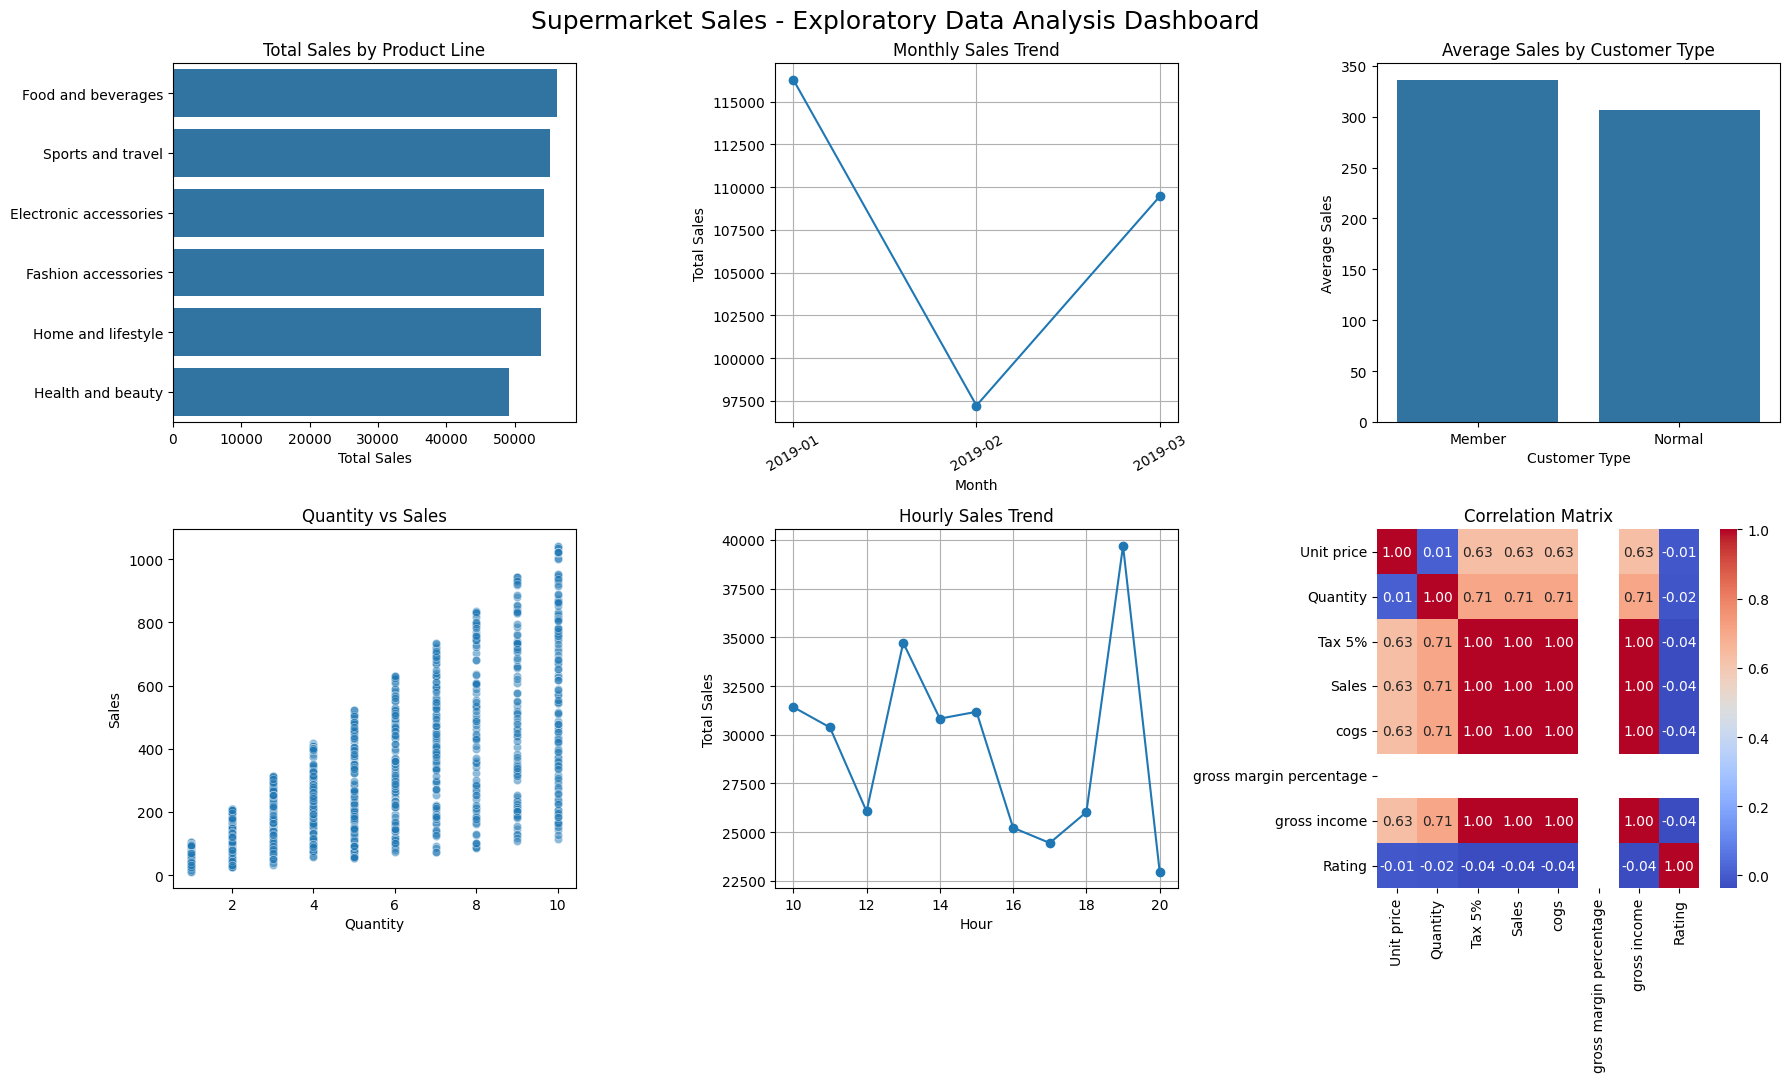

EDA dashboard saved successfully!


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. Product line total sales
product_total = df.groupby("Product line")["Sales"].sum().sort_values(ascending=False)
sns.barplot(x=product_total.values, y=product_total.index, ax=axes[0, 0])
axes[0, 0].set_title("Total Sales by Product Line")
axes[0, 0].set_xlabel("Total Sales")
axes[0, 0].set_ylabel("")

# 2. Monthly sales
axes[0, 1].plot(monthly_sales.index, monthly_sales.values, marker="o")
axes[0, 1].set_title("Monthly Sales Trend")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Total Sales")
axes[0, 1].tick_params(axis="x", rotation=30)
axes[0, 1].grid(True)

# 3. Customer type average sales
customer_sales = df.groupby("Customer type")["Sales"].mean()
sns.barplot(x=customer_sales.index, y=customer_sales.values, ax=axes[0, 2])
axes[0, 2].set_title("Average Sales by Customer Type")
axes[0, 2].set_xlabel("Customer Type")
axes[0, 2].set_ylabel("Average Sales")

# 4. Quantity vs Sales
sns.scatterplot(data=df, x="Quantity", y="Sales", alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_title("Quantity vs Sales")
axes[1, 0].set_xlabel("Quantity")
axes[1, 0].set_ylabel("Sales")

# 5. Hourly sales
axes[1, 1].plot(
    hourly_sales.index,
    hourly_sales["Total_Sales"],
    marker="o"
)
axes[1, 1].set_title("Hourly Sales Trend")
axes[1, 1].set_xlabel("Hour")
axes[1, 1].set_ylabel("Total Sales")
axes[1, 1].grid(True)

# 6. Correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Correlation Matrix")

plt.suptitle(
    "Supermarket Sales - Exploratory Data Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "/content/supermarket_eda_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("EDA dashboard saved successfully!")